# ML LAB 8
## Name:Akshay Tripathi
## Roll no: C-C1-16

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import  train_test_split,GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC

from sklearn.metrics import ( accuracy_score,classification_report,confusion_matrix,roc_curve,f1_score,recall_score,precision_score,ConfusionMatrixDisplay)

import warnings
warnings.filterwarnings('ignore')

In [ ]:
df=pd.read_csv('/content/ai4i2020 - ai4i2020.csv')

In [ ]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [ ]:
df.shape

(10000, 14)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [ ]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [ ]:
df.isnull().sum()

,0
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


In [ ]:
df.duplicated().sum()

np.int64(0)

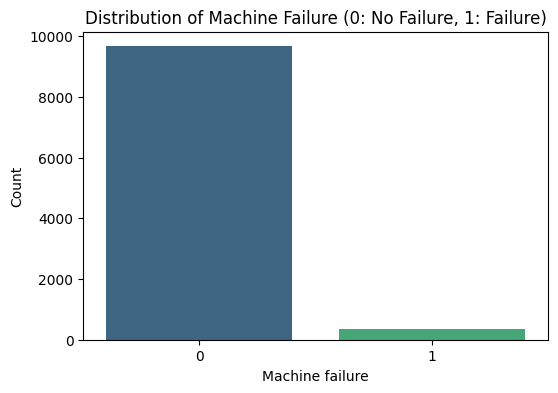

In [ ]:
# Step 1: Check the Target Variable Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='Machine failure', data=df, palette='viridis')
plt.title('Distribution of Machine Failure (0: No Failure, 1: Failure)')
plt.xlabel('Machine failure')
plt.ylabel('Count')
plt.show()

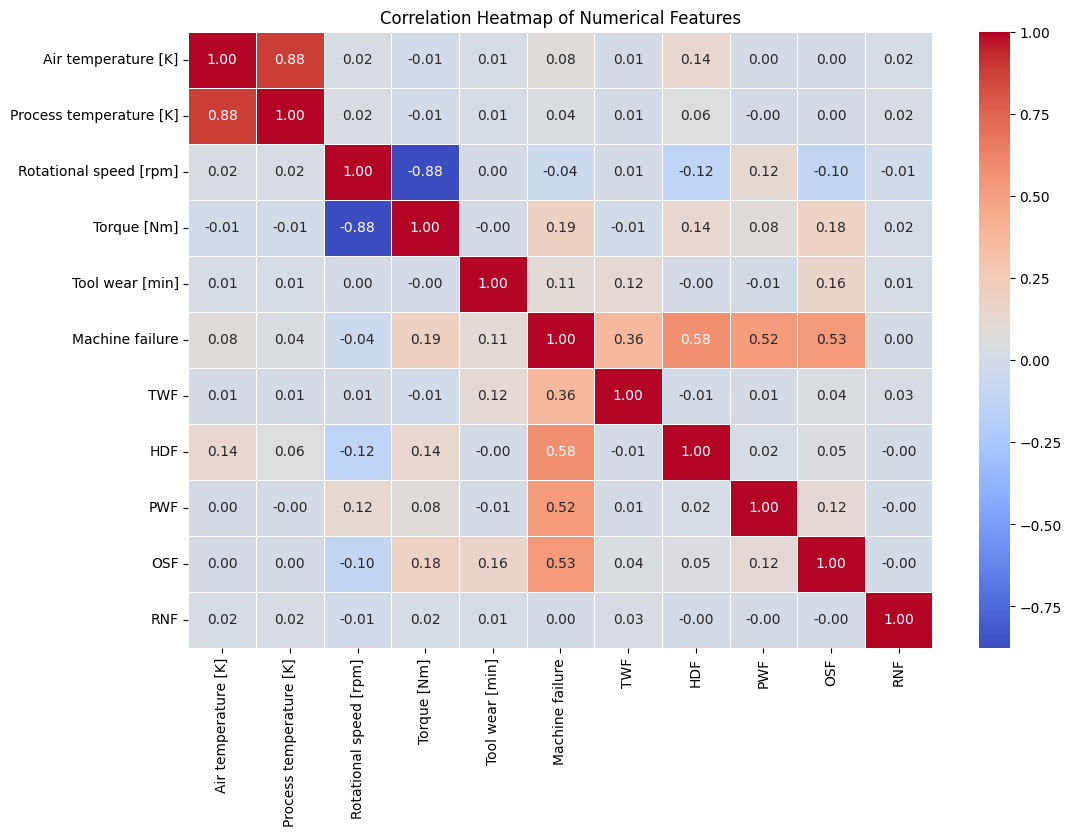

In [ ]:
# Step 2: Correlation Heatmap
plt.figure(figsize=(12, 8))
# Select only numerical features and drop the UDI column
numeric_df = df.select_dtypes(include=[np.number]).drop(columns=['UDI'])

# Plot heatmap
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

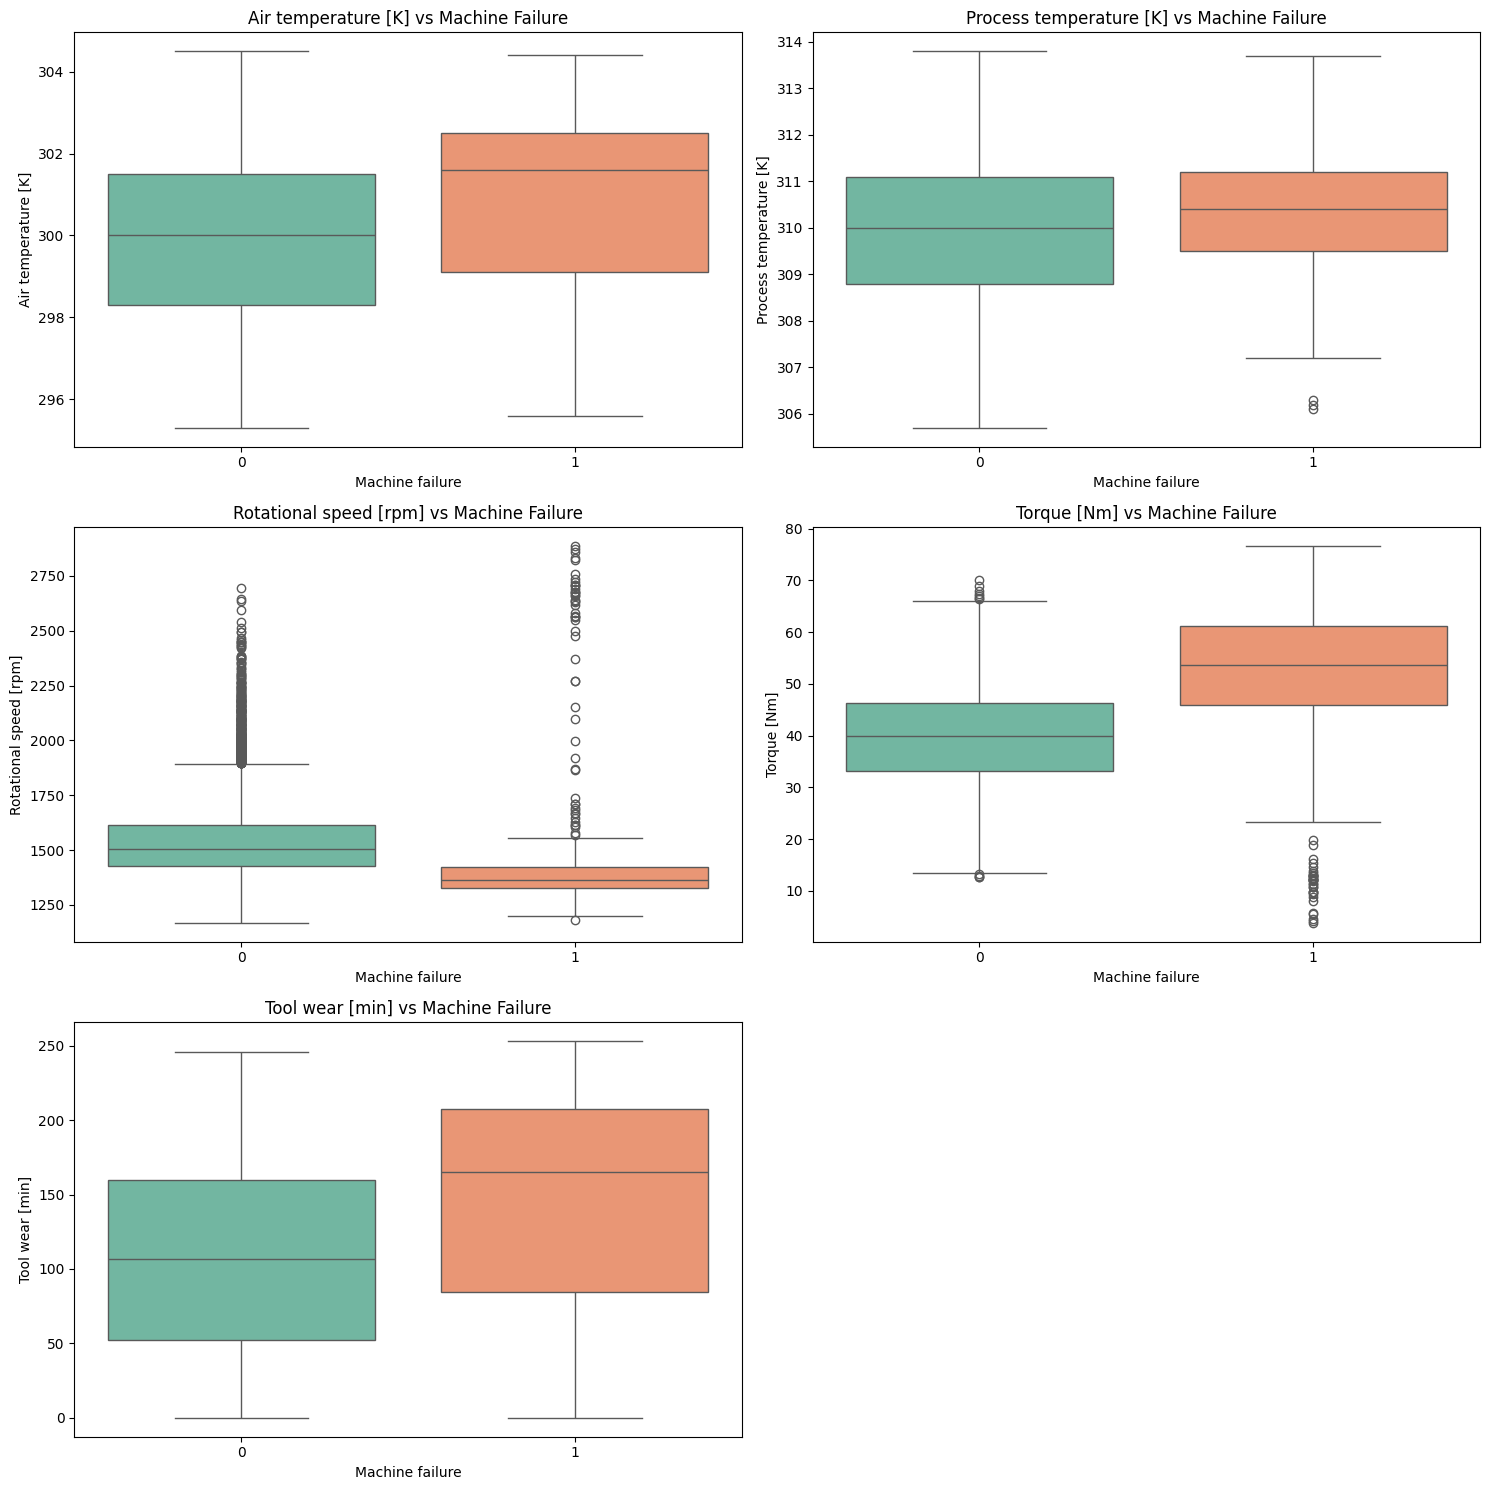

In [ ]:
# Step 3: Numerical Features vs. Machine Failure (Boxplots)
# List of key sensor features
sensor_features = ['Air temperature [K]', 'Process temperature [K]',
                   'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

fig, axes = plt.subplots(3, 2, figsize=(15, 15))
axes = axes.flatten()

for i, col in enumerate(sensor_features):
    sns.boxplot(x='Machine failure', y=col, data=df, ax=axes[i], palette='Set2')
    axes[i].set_title(f'{col} vs Machine Failure')

# Remove the empty 6th subplot
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

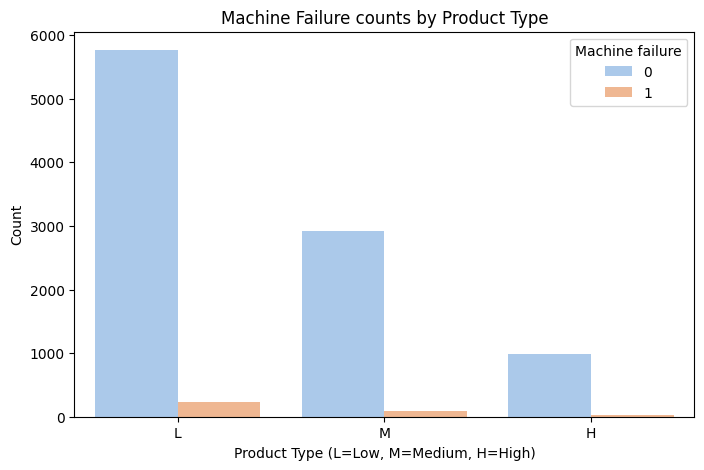

In [ ]:
# Step 4: Product Type Distribution
plt.figure(figsize=(8, 5))
sns.countplot(x='Type', hue='Machine failure', data=df, palette='pastel', order=['L', 'M', 'H'])
plt.title('Machine Failure counts by Product Type')
plt.xlabel('Product Type (L=Low, M=Medium, H=High)')
plt.ylabel('Count')
plt.show()

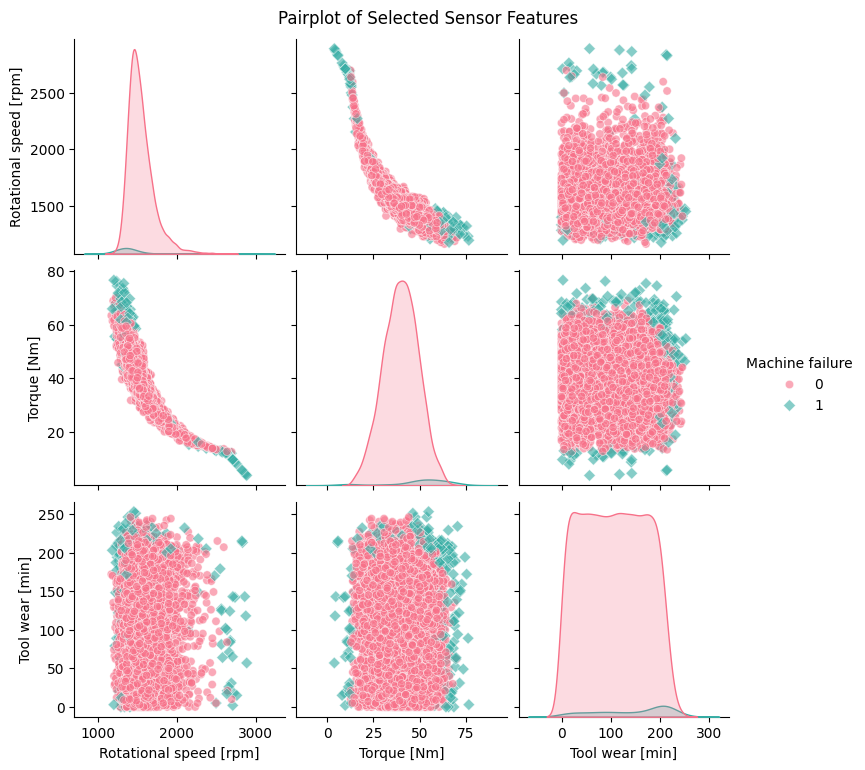

In [ ]:
# Step 5: Pairplot for a Deeper Look (Optional)
# Selecting a subset of features to keep the plot readable
subset_cols = ['Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure']

sns.pairplot(df[subset_cols], hue='Machine failure', palette='husl', markers=["o", "D"], plot_kws={'alpha':0.6})
plt.suptitle('Pairplot of Selected Sensor Features', y=1.02)
plt.show()

In [ ]:
# making data ready for algo application
X=df[
    [   'Type',
        'Air temperature [K]',
        'Process temperature [K]',
        'Rotational speed [rpm]',
        'Torque [Nm]',
        'Tool wear [min]'
    ]
]

In [ ]:
y=df["Machine failure"]

In [ ]:
print(X.shape) # i/p shape
print(y.shape) # o/p shape

(10000, 6)
(10000,)


In [ ]:
categorical_features=['Type']
numerical_features=['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("training samples:",X_train.shape)
print("testing samples:",X_test.shape)

training samples: (8000, 6)
testing samples: (2000, 6)


In [ ]:
preprocessor=ColumnTransformer(
    [
        ('num_pipeline',StandardScaler(),numerical_features),
        ('cat_pipeline',OneHotEncoder(),categorical_features)
    ]
)

In [ ]:
linear_svm=Pipeline([
    ('preprocessor',preprocessor),
    ('classifier',SVC(kernel='linear'))
])
# train model
linear_svm.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num_pipeline',
                                                  StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat_pipeline',
                                                  OneHotEncoder(),
                                                  ['Type'])])),
                ('classifier', SVC(kernel='linear'))])

In [ ]:
y_pred_linear=linear_svm.predict(X_test)

In [ ]:
accuracy_linear=accuracy_score(y_test,y_pred_linear)
precision_linear=precision_score(y_test,y_pred_linear,zero_division=0)
recall_linear=recall_score(y_test,y_pred_linear,zero_division=0)
f1_linear=f1_score(y_test,y_pred_linear,zero_division=0)

print("Accuracy:",accuracy_linear)
print("Precision:",precision_linear)
print("Recall:",recall_linear)
print("F1 Score:",f1_linear)

Accuracy: 0.966
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


Classification Report:
              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.98      1932
     Failure       0.00      0.00      0.00        68

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.93      0.97      0.95      2000



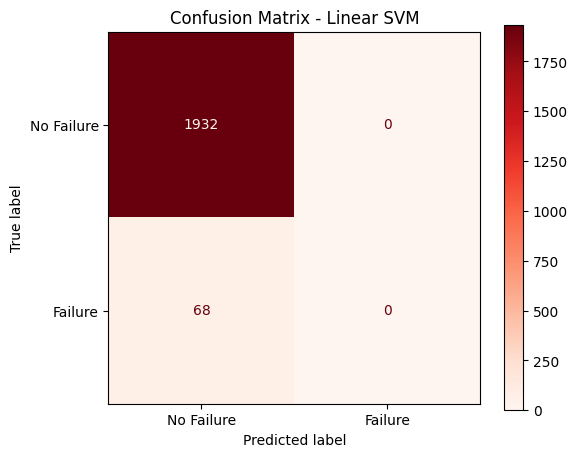

In [ ]:
# Print the classification report
print("Classification Report:")
print(classification_report(y_test, y_pred_linear, target_names=["No Failure", "Failure"]))

# Compute and plot the confusion matrix
cm = confusion_matrix(y_test, y_pred_linear)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Failure", "Failure"])

# Plotting
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap='Reds', ax=ax)
plt.title("Confusion Matrix - Linear SVM")
plt.show()

In [ ]:
rbf_svm=Pipeline([
    ('preprocessor',preprocessor),
    ('classifier',SVC(kernel='rbf'))
])
# train model
rbf_svm.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num_pipeline',
                                                  StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat_pipeline',
                                                  OneHotEncoder(),
                                                  ['Type'])])),
                ('classifier', SVC())])

In [ ]:
y_pred_rbf=rbf_svm.predict(X_test)

In [ ]:
# Calculate metrics for RBF SVM
accuracy_rbf = accuracy_score(y_test, y_pred_rbf)
precision_rbf = precision_score(y_test, y_pred_rbf, zero_division=0)
recall_rbf = recall_score(y_test, y_pred_rbf, zero_division=0)
f1_rbf = f1_score(y_test, y_pred_rbf, zero_division=0)

# Print metrics
print("Accuracy (RBF):", accuracy_rbf)
print("Precision (RBF):", precision_rbf)
print("Recall (RBF):", recall_rbf)
print("F1 Score (RBF):", f1_rbf)

Accuracy (RBF): 0.972
Precision (RBF): 0.875
Recall (RBF): 0.20588235294117646
F1 Score (RBF): 0.3333333333333333


Classification Report (RBF SVM):
              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.99      1932
     Failure       0.88      0.21      0.33        68

    accuracy                           0.97      2000
   macro avg       0.92      0.60      0.66      2000
weighted avg       0.97      0.97      0.96      2000



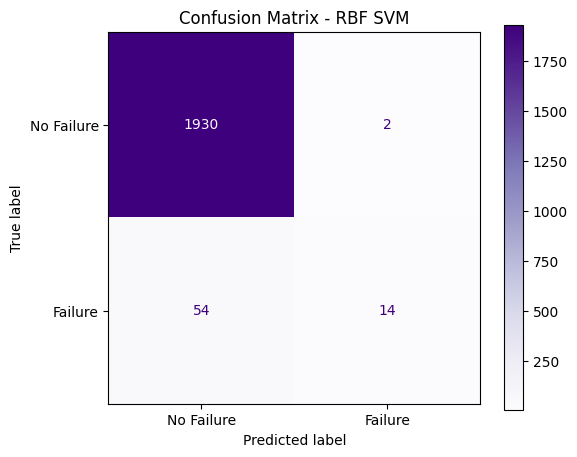

In [ ]:
# Print the classification report
print("Classification Report (RBF SVM):")
print(classification_report(y_test, y_pred_rbf, target_names=["No Failure", "Failure"], zero_division=0))

# Compute and plot the confusion matrix
cm_rbf = confusion_matrix(y_test, y_pred_rbf)
disp_rbf = ConfusionMatrixDisplay(confusion_matrix=cm_rbf, display_labels=["No Failure", "Failure"])

# Plotting
fig, ax = plt.subplots(figsize=(6, 5))
disp_rbf.plot(cmap='Purples', ax=ax) # Using 'Purples' to distinguish from your Linear SVM plot
plt.title("Confusion Matrix - RBF SVM")
plt.show()

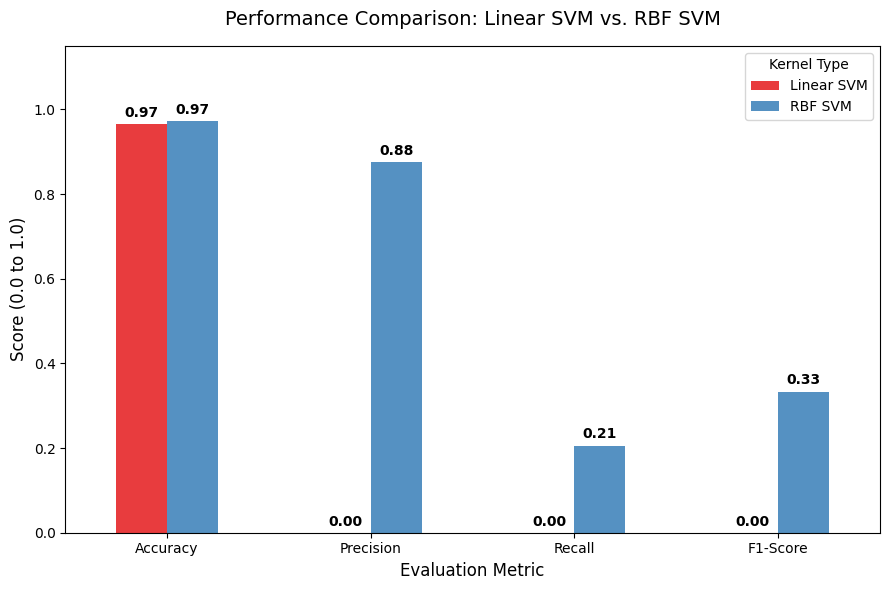

In [ ]:
# Create a DataFrame to hold the metrics for both models
metrics_data = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Linear SVM': [accuracy_linear, precision_linear, recall_linear, f1_linear],
    'RBF SVM': [accuracy_rbf, precision_rbf, recall_rbf, f1_rbf]
}

metrics_df = pd.DataFrame(metrics_data)

# Set the 'Metric' column as the index for easier plotting
metrics_df.set_index('Metric', inplace=True)

# Plot a grouped bar chart
fig, ax = plt.subplots(figsize=(9, 6))
metrics_df.plot(kind='bar', ax=ax, color=['#e41a1c', '#377eb8'], alpha=0.85)

# Formatting the plot
plt.title('Performance Comparison: Linear SVM vs. RBF SVM', fontsize=14, pad=15)
plt.ylabel('Score (0.0 to 1.0)', fontsize=12)
plt.xlabel('Evaluation Metric', fontsize=12)
plt.ylim(0, 1.15)  # Set limit slightly above 1 for labels to fit
plt.xticks(rotation=0)
plt.legend(title='Kernel Type')

# Add the exact value scores on top of each bar
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 8),
                textcoords='offset points', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
# Step 1: Define the Hyperparameter Grid
# C = Regularization (lower is smoother, higher is more complex)
# gamma = Influence radius of data points
param_grid = {
    'classifier__C': [0.1, 1, 10],
    'classifier__gamma': ['scale', 0.1, 1],
    'classifier__class_weight': ['balanced'] # Crucial for your imbalanced dataset
}

# Step 2: Initialize GridSearchCV
# We score based on 'f1' or 'recall' because standard accuracy is misleading here
grid_search = GridSearchCV(
    estimator=rbf_svm,         # Your existing pipeline from cell [37]
    param_grid=param_grid,
    cv=3,                      # 3-fold cross-validation (keeps run time manageable)
    scoring='f1',              # Optimizing for F1-score rather than accuracy
    verbose=2,                 # Prints the progress out
    n_jobs=-1                  # Uses all available CPU cores
)

# Step 3: Fit the Grid Search
print("Starting Stepwise Hyperparameter Tuning...")
grid_search.fit(X_train, y_train)

# Step 4: Output the Best Parameters
print("\nBest Hyperparameters Found:")
print(grid_search.best_params_)

Starting Stepwise Hyperparameter Tuning...
Fitting 3 folds for each of 9 candidates, totalling 27 fits

Best Hyperparameters Found:
{'classifier__C': 10, 'classifier__class_weight': 'balanced', 'classifier__gamma': 1}


In [ ]:
y_pred_tuned = grid_search.predict(X_test)

# Calculate metrics for the tuned model
accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
precision_tuned = precision_score(y_test, y_pred_tuned,zero_division=0)
recall_tuned = recall_score(y_test, y_pred_tuned,zero_division=0)
f1_tuned = f1_score(y_test, y_pred_tuned,zero_division=0)
print(" Total SVM results")
print("Accuracy:", accuracy_tuned)
print("Precision:", precision_tuned)
print("Recall:", recall_tuned)
print("F1 Score:", f1_tuned)

 Total SVM results
Accuracy: 0.961
Precision: 0.4431818181818182
Recall: 0.5735294117647058
F1 Score: 0.5


--- Detailed Model Performance Comparison ---


,Linear SVM,Untuned RBF SVM,Tuned RBF SVM
Metric,,,
Accuracy,0.966,0.972,0.961
Precision,0.000,0.875,0.443
Recall,0.000,0.206,0.574
F1-Score,0.000,0.333,0.500


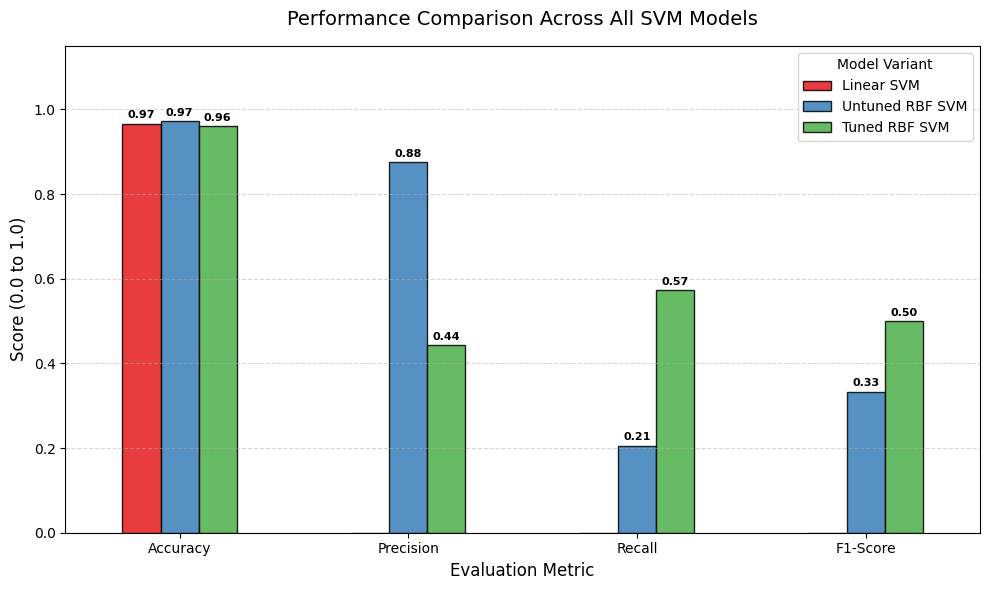

In [ ]:
# Create a DataFrame combining metrics from all three models
comparison_data = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Linear SVM': [accuracy_linear, precision_linear, recall_linear, f1_linear],
    'Untuned RBF SVM': [accuracy_rbf, precision_rbf, recall_rbf, f1_rbf],
    'Tuned RBF SVM': [accuracy_tuned, precision_tuned, recall_tuned, f1_tuned]
}

comparison_df = pd.DataFrame(comparison_data).set_index('Metric')

# Display numerical comparison table
print("--- Detailed Model Performance Comparison ---")
display(comparison_df.round(3))

# Plot grouped bar chart
fig, ax = plt.subplots(figsize=(10, 6))
comparison_df.plot(
    kind='bar',
    ax=ax,
    color=['#e41a1c', '#377eb8', '#4daf4a'],
    alpha=0.85,
    edgecolor='black'
)

# Chart formatting
plt.title('Performance Comparison Across All SVM Models', fontsize=14, pad=15)
plt.ylabel('Score (0.0 to 1.0)', fontsize=12)
plt.xlabel('Evaluation Metric', fontsize=12)
plt.ylim(0, 1.15)
plt.xticks(rotation=0)
plt.legend(title='Model Variant', loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Annotate exact score values on top of each bar
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f"{height:.2f}",
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='center',
            xytext=(0, 6), textcoords='offset points',
            fontsize=8, fontweight='bold'
        )

plt.tight_layout()
plt.show()